# Figure 3: database transfer, pooling and quantitative agreement

Figure 3 uses the 58 healthy-stool acquisitions in five sampling series. It shows how much of an
acquisition's peptide identification is kept when its database is selected from another
acquisition (b, c), what pooling the databases of 12 technical replicates adds (d, e), and how
closely protein-group and KEGG-ortholog intensities agree between acquisition pairs (f).
Panel a is a schematic. Panels b-e use 9-50-residue peptides (v30).

Run from the repository root: `python paper.py build Fig3`. Set `FASTALAKE_FONT_DIR` to the Söhne
fonts (`soehne-buch.otf`, `soehne-buch.ttf`, `soehne-halbfett.ttf`) for the pixel checks.

In [1]:
from pathlib import Path
import sys
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl
import panels
fl.init()

import json
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 160)
d = panels.load(SD)
print({k: v.shape for k, v in d.items()})

{'comparisons': (420, 17), 'pg': (1896, 8), 'ko': (1264, 7), 'design': (58, 15)}


## Panel a

Schematic of the five healthy-stool sampling series (artwork, not regenerated). Supports
"We next used the 58 healthy-stool acquisitions, which form five sampling series" (v28d line 99).
n: 58 acquisitions (12, 15, 10, 11 and 10 per series). No test. Every typed number is traced in
`ARTWORK_NUMBERS.md`; the counts below are recomputed from the transfer table.

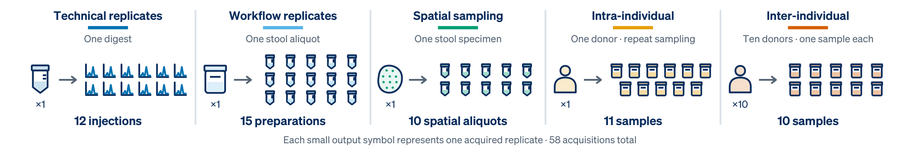

{'per_design': {'TechnicalReplicates': 12, 'WorkflowReplicates': 15, 'OnePiece': 10, 'Intra': 11, 'Interindividual': 10}, 'total': 58, 'n_designs': 5}


In [2]:
display(Image(filename=str(panels.preview(panels.render_artwork(UNIT / "artwork" / "panel_a_design.pdf", OUT / "panel_a.png")))))
print(panels.stat_a_design_counts(d["comparisons"]))


## Panel b

Peptide count with a transferred database as a percentage of the own-database count, for a
same-series donor (T1, blue; legend "Same series") and a different-donor database (T4, orange;
legend "Different donor"). Supports "retained a median 96.0% of the 9–50-residue peptide count ...
retaining 55.8% of the peptide count" (v30 paragraph 48; v28d line 99 printed the 5-50 values).
n: 58 target acquisitions (12, 15, 10, 11, 10 per series), one T1 and one T4 search each.
Descriptive medians; no test. The original producer drew b, c, d and e on one canvas, so they are
rendered together here; the legend relabel is a composite step (`assemble_v30`, final cell).


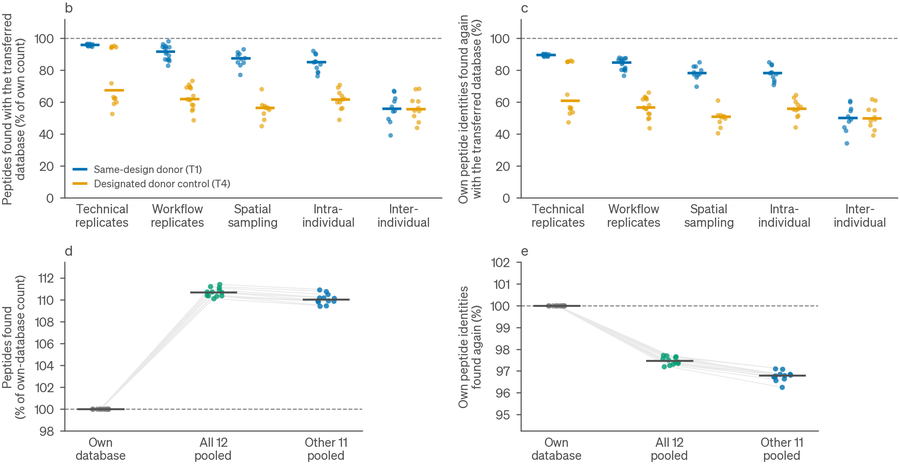

               arm              design                   field    median        q1        q3   minimum   maximum  n
   T1_within_group TechnicalReplicates count_retention_percent 95.953743 95.464857 96.236310 94.823140 96.624095 12
   T1_within_group  WorkflowReplicates count_retention_percent 91.748919 86.899014 94.655091 83.070490 98.150337 15
   T1_within_group            OnePiece count_retention_percent 87.436053 84.941411 90.098118 77.106454 93.146186 10
   T1_within_group               Intra count_retention_percent 85.060987 80.359076 87.787216 76.321890 92.161197 11
   T1_within_group     Interindividual count_retention_percent 55.825569 50.602736 61.897510 39.320304 67.036467 10
T4_different_donor TechnicalReplicates count_retention_percent 67.430408 61.657173 94.363375 52.584698 95.442380 12
T4_different_donor  WorkflowReplicates count_retention_percent 61.960704 58.398191 69.410867 48.627019 73.566954 15
T4_different_donor            OnePiece count_retention_percent 56.418205

In [3]:
res_bcde = panels.panels_bcde(d["comparisons"], OUT / "panel_bcde")
display(Image(filename=str(panels.preview(OUT / "panel_bcde.png"))))
bc = panels.stat_bc_transfer(d["comparisons"])
print(bc[bc.field.eq("count_retention_percent")].to_string(index=False))


## Panel c

Recovery of the own-database peptide identities with the transferred database. Supports "89.6% of
the peptide identities ... 50.2% of peptide identities" (v30 paragraph 48; v28d line 99). n as in
panel b. Descriptive medians; no test.


In [4]:
print(bc[bc.field.eq("own_set_recovery_percent")].to_string(index=False))


               arm              design                    field    median        q1        q3   minimum   maximum  n
   T1_within_group TechnicalReplicates own_set_recovery_percent 89.554877 89.157449 89.939644 88.362052 90.430108 12
   T1_within_group  WorkflowReplicates own_set_recovery_percent 84.662305 80.654796 87.008145 76.666576 87.908309 15
   T1_within_group            OnePiece own_set_recovery_percent 78.302867 77.114575 81.761011 69.793797 85.127263 10
   T1_within_group               Intra own_set_recovery_percent 78.325478 74.658212 81.057688 70.723110 85.036558 11
   T1_within_group     Interindividual own_set_recovery_percent 50.151003 45.077972 55.456720 34.135890 60.841871 10
T4_different_donor TechnicalReplicates own_set_recovery_percent 60.734085 55.402276 85.451964 47.306391 86.150031 12
T4_different_donor  WorkflowReplicates own_set_recovery_percent 56.479738 52.752708 62.238854 43.780680 66.115116 15
T4_different_donor            OnePiece own_set_recovery_percent 

## Panel d

Peptide count of each technical replicate searched against its own database, the union of all 12
replicate databases and the union of the other 11, as a percentage of the own-database count.
Supports "increased 9–50-residue peptide identifications in every acquisition by a median 10.0%"
and "(+10.7%, 97.5% retained)" (v30 paragraph 50; v28d line 103). The gained and lost medians
printed in v28d line 103 are no longer printed in v30. n: 12 acquisitions (repeated injections
of one digest). Descriptive medians; no test.


In [5]:
de = panels.stat_de_pool(d["comparisons"])
for arm, v in de.items():
    print(arm, "count", v["count"], "gained", v["median_gained"], "lost", v["median_lost"],
          "acquisitions with more peptides", v["acquisitions_with_more_peptides"], "of", v["n"])


own count {'median': 100.0, 'q1': 100.0, 'q3': 100.0, 'minimum': 100.0, 'maximum': 100.0, 'n': 12} gained 0.0 lost 0.0 acquisitions with more peptides 0 of 12
pool_all12 count {'median': 110.68969993876263, 'q1': 110.37370577596722, 'q3': 110.95267580300934, 'minimum': 110.09622727967007, 'maximum': 111.42335908085238, 'n': 12} gained 3399.5 lost 652.0 acquisitions with more peptides 12 of 12
pool_other11 count {'median': 110.01501377341805, 'q1': 109.84206002819671, 'q3': 110.25786633736459, 'minimum': 109.4203451962731, 'maximum': 110.91099639017196, 'n': 12} gained 3430.5 lost 832.0 acquisitions with more peptides 12 of 12


## Panel e

Recovery of the own-database peptide identities with the pooled databases. Supports "while
retaining 96.8% of identities from the acquisition-specific search" (v30 paragraph 50; v28d
line 103). n: 12 acquisitions. Descriptive medians; no test.


In [6]:
for arm, v in de.items():
    print(arm, "identity", v["identity"])

own identity {'median': 100.0, 'q1': 100.0, 'q3': 100.0, 'minimum': 100.0, 'maximum': 100.0, 'n': 12}
pool_all12 identity {'median': 97.4698678538369, 'q1': 97.34753673199829, 'q3': 97.63887013048411, 'minimum': 97.19164494923956, 'maximum': 97.71778671261728, 'n': 12}
pool_other11 identity {'median': 96.78920209958133, 'q1': 96.69854581886264, 'q3': 96.84801625669165, 'minimum': 96.24645065930218, 'maximum': 97.09661141947754, 'n': 12}


## Panel f

Pairwise agreement within each sampling series. Upper row: protein groups (host pairs above the
diagonal, microbial below). Lower row: KEGG orthologs (all origins above, human-assigned signal
excluded below). Labels: median Pearson r of log2 intensities, median raw-intensity CV and median
number of jointly quantified features across pairs. Supports v28d line 109 / v30 paragraph 54
("21% ... 52%", "0.82 to 0.48", "0.90 ... 0.81", "more strongly correlated ... in every sampling
design") and the legend. Unchanged in v30 (no 9-50 counterpart in its producers). n: 66, 105, 45,
55 and 45 acquisition pairs from 12, 15, 10, 11 and 10 acquisitions; pairs share acquisitions and
are not independent. Descriptive medians; no test.


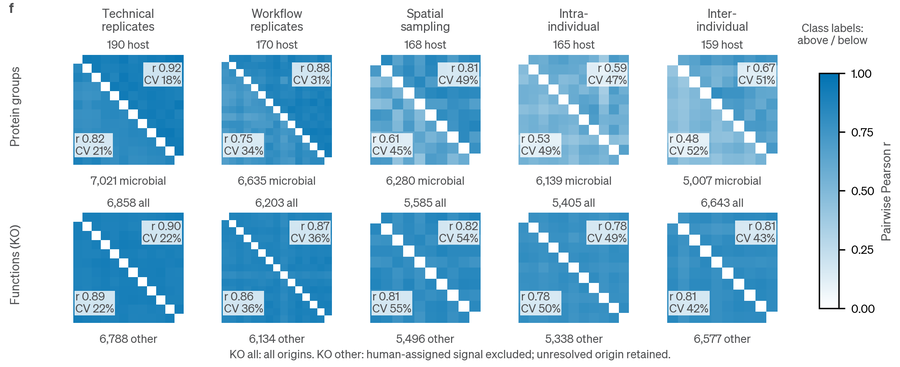

against the producer receipt: {'summary_equal': 20, 'summary_total': 20, 'matrices_equal': 10, 'matrices_total': 10}
         space              design                  cls  n_pairs  median_r  median_cv  median_features     r_q1     r_q3     cv_q1     cv_q3
protein groups TechnicalReplicates                 host       66  0.915592  18.491939            190.0 0.898560 0.926858 14.140981 22.490561
protein groups TechnicalReplicates            microbial       66  0.821639  21.073313           7021.0 0.794703 0.834678 17.054081 25.124179
protein groups  WorkflowReplicates                 host      105  0.878653  30.538066            170.0 0.859118 0.897158 25.558196 40.434319
protein groups  WorkflowReplicates            microbial      105  0.747371  33.553896           6635.0 0.721133 0.777403 28.038399 40.609407
protein groups            OnePiece                 host       45  0.807665  49.238152            168.0 0.733458 0.827297 33.727821 68.250133
protein groups            OnePiece   

In [7]:
res_f = panels.panel_f(d["pg"], d["ko"], d["design"], OUT / "panel_f")
display(Image(filename=str(panels.preview(OUT / "panel_f.png"))))
receipt = json.loads((UNIT / "expected" / "panel_f_producer_receipt.json").read_text())
print("against the producer receipt:", panels.check_panel_f_receipt(res_f, receipt))
fs = panels.stat_f_summaries(d["pg"], d["ko"])
print(fs.to_string(index=False))
print(panels.stat_f_ko_vs_microbial_pg(fs).to_string(index=False))


## Checks and numbers

Pixel checks compare each regenerated panel with the panel rendered by the original producer
(`expected/`), at 300 dpi: b-e against the v30 (9-50) producer render, f against the v28f
producer render (f is unchanged in v30). Band checks place each panel where the assembly chain
placed it and compare that band with the v30 vector composite (`expected/Fig3_v30_vector.pdf`);
they differ where the chain re-typeset text (`ASSEMBLY.md`) and are recorded as visual checks.
The composite check rebuilds the whole v30 page with `assemble_v30` and compares it with the
v30 figure PNG (`expected/Fig3_v30.png`). Then every value in `NUMBERS.tsv` is printed, followed by the donor assignments.


In [8]:
from tools.check_pixels import compare
CHK = UNIT / "checks"
if panels.fonts_present():
    for x in ["bcde", "f"]:
        r = compare(OUT / f"panel_{x}.pdf", UNIT / "expected" / f"panel_{x}.pdf", CHK / f"panel_{x}", dpi=300)
        print(f"panel {x}:", r["verdict"], r.get("differing_pixels"))
    rects = panels.composite_rects()
    for x, src in [("a", UNIT / "artwork" / "panel_a_design.pdf"), ("bcde", OUT / "panel_bcde.pdf"), ("f", OUT / "panel_f.pdf")]:
        r = panels.composite_band_check(src, UNIT / "expected" / "Fig3_v30_vector.pdf", rects[x],
                                        CHK / f"composite_band_{x}", OUT / "bands")
        print(f"v30 band {x}:", r["verdict"], r.get("differing_pixels"), r.get("differing_fraction"))
    comp = panels.assemble_v30(OUT / "panel_bcde.pdf", UNIT / "expected" / "Fig3_v28f_relabel_base.pdf", OUT / "Fig3_v30")
    r = compare(comp["png"], UNIT / "expected" / "Fig3_v30.png", CHK / "composite_v30", dpi=300)
    print("v30 composite:", r["verdict"], r.get("differing_pixels"), "retyped spans", comp["retyped_spans"])
else:
    print("pixel checks SKIPPED: fonts absent")

for key, value in panels.numbers(d):
    print(f"{key}\t{value}")
print(panels.stat_methods_donor_assignments(d["comparisons"]))


panel bcde: IDENTICAL 0
panel f: IDENTICAL 0


v30 band a: DIFFERENT 9037 0.011578742366896353


v30 band bcde: DIFFERENT 65654 0.02718643916198818


v30 band f: DIFFERENT 10629 0.00581120711712953


v30 composite: IDENTICAL 0 retyped spans 72
L99 acquisitions	58
L99 series	five
L99 technical count	95.95374313839133
L99 technical identity	89.5548765349636
L99 interindividual count	55.8255693663166
L99 interindividual identity	50.15100294165582
L103 technical replicates	12
L103 other injections	11
L103 median gain %	10.015013773418048
L103 identity retained	96.78920209958133
L103 median gained	3430.5
L103 median lost	832.0
L107 five series (a)	five
L107 ten-donor series	ten
L107 all 12	12
L107 other 11	11
L107 five series (f)	five
L109 five series	five
L109 microbial PG CV technical	21.073313105192938
L109 microbial PG CV interindividual	52.07203244252325
L109 microbial PG r technical	0.8216390692410767
L109 microbial PG r interindividual	0.4831057614351533
L109 KO r technical	0.8951563068271853
L109 KO r interindividual	0.8099346902420237
L739 acquisitions	58
L739 inter-individual acquisitions	ten
L739 inter-individual targets	ten
L739 differ	nine
L739 coincide	one
v30 P50 all-12 g